In [8]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Lattice visualization

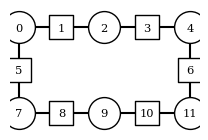

In [9]:
from z2hex.geometry import HeavyHexLattice

hplaquettes = 1
vplaquettes = 1

lattice = HeavyHexLattice(hplaquettes, vplaquettes)
lattice.plot_lattice(number_qubits=True)

# Noiseless Circuit

## Simulation settings

In [10]:
lattice_dimensions_arr = [(1, 1)]
J_arr = [1]
h_arr = [0.3]
lamb_arr = [0.3]
g_arr = [None]

x_basis = False

strings_arr = [
    (0, 1, 3, 6, 11)
]

final_time = 25
steps = 100

max_layers = 200

shots = 75000
flip_threshold = 2

first_layout_qubit = 0
error = 1e-2

sampler_options = {"default_shots": shots}
simulator_options = {
    "method": "matrix_product_state",
    "matrix_product_state_max_bond_dimension": 512,
    "matrix_product_state_truncation_threshold": 1e-12
}

## Circuit generation & observables

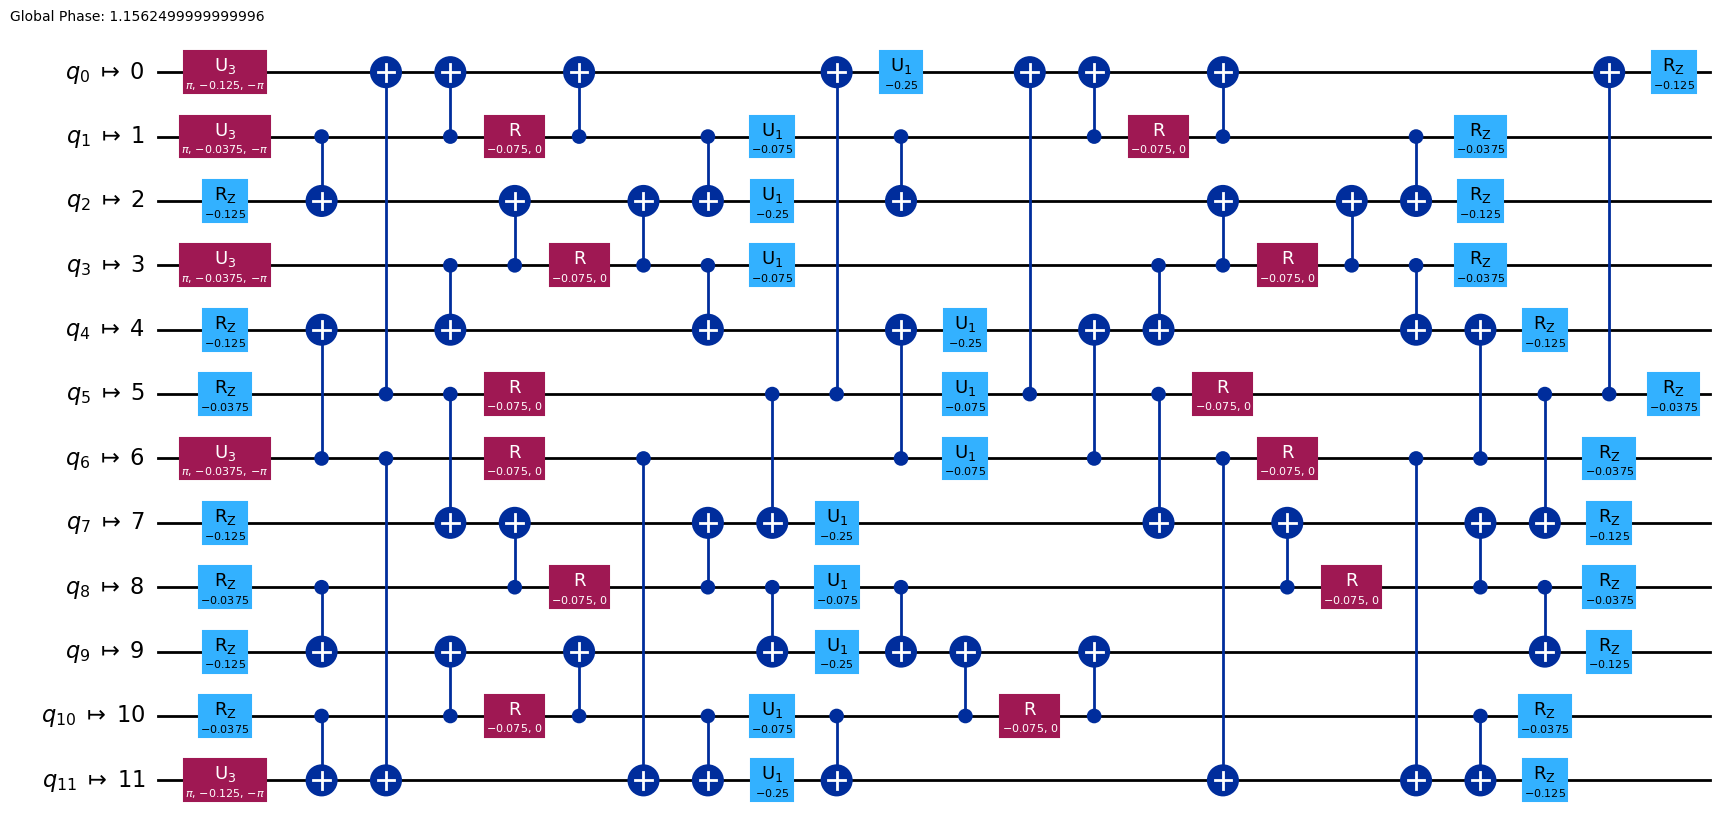

In [11]:
from z2hex.circs import erradj_string_quench_simulation_circuits_eplg, odr_compuncomp_circuits_eplg
from z2hex.operators import local_pauli_x, local_pauli_z, postselection_operators
from z2hex.geometry import HeavyHexLattice
from qiskit_aer import AerSimulator
from itertools import product
import os

fake_backend = AerSimulator(**simulator_options)

optimization_level = 3

circuits = []
observable_generating_funcs = [] # observable_generating_funcs[dims][i]
postselection_operators_funcs = [] # postselection_operators_funcs[dims][i]

for (px, py), string_arr in zip(lattice_dimensions_arr, strings_arr):
    this_circuits = []
    lattice = HeavyHexLattice(px, py)
    for J, h, lamb, g in product(J_arr, h_arr, lamb_arr, g_arr):
        circs_args = (lattice, J, h, lamb, string_arr, final_time, steps, fake_backend, optimization_level, error, g, first_layout_qubit, x_basis, False, max_layers)
        physical_circuits = erradj_string_quench_simulation_circuits_eplg(*circs_args)
        this_circuits.append(physical_circuits)
    circuits.append(this_circuits)
    observable_generating_funcs.append([(lambda nqubits, i=i: local_pauli_x(lattice, i) if x_basis else local_pauli_z(lattice, i)) for i in range(len(lattice))])
    postselection_operators_funcs.append(lambda nqubits: postselection_operators(lattice, x_basis))

circuits[0][0][1].draw(output="mpl", idle_wires=False)

In [12]:
from utils.circs import depth2qb

[depth2qb(circ) for circ in circuits[0][0]]

[0,
 12,
 18,
 18,
 24,
 30,
 36,
 36,
 42,
 48,
 48,
 54,
 60,
 60,
 66,
 72,
 72,
 78,
 78,
 84,
 84,
 90,
 96,
 96,
 102,
 102,
 108,
 108,
 114,
 114,
 120,
 120,
 126,
 126,
 132,
 132,
 138,
 138,
 144,
 144,
 150,
 150,
 156,
 156,
 162,
 162,
 168,
 168,
 174,
 174,
 180,
 180,
 186,
 186,
 192,
 192,
 198,
 198,
 204,
 204,
 210,
 210,
 216,
 216,
 216,
 222,
 222,
 228,
 228,
 234,
 234,
 240,
 240,
 246,
 246,
 252,
 252,
 258,
 258,
 258,
 264,
 264,
 270,
 270,
 276,
 276,
 282,
 282,
 288,
 288,
 294,
 294,
 294,
 300,
 300,
 306,
 306,
 312,
 312,
 318,
 318]

In [13]:
from utils.postselection import simulate_postselected_operators
from z2hex.plotting import local_obs_anim
from z2hex.geometry import HeavyHexLattice

interpolation_frames = 0
fps = 1
frame_to_title_func = lambda frame: f"$t = {final_time * frame / ((interpolation_frames+1)*steps):.02f}$"

for i, ((px, py), string_arr) in enumerate(zip(lattice_dimensions_arr, strings_arr)):
    lattice = HeavyHexLattice(px, py)
    for j, (J, h, lamb, g) in enumerate(product(J_arr, h_arr, lamb_arr, g_arr)):
        observables = simulate_postselected_operators(fake_backend, sampler_options, circuits[i][j], postselection_operators_funcs[i], observable_generating_funcs[i])
        local_obs_anim((1 - observables)/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, filepath=f"z2hex_string_quench_simulation_tn_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4")

ffmpeg version 7.1 Copyright (c) 2000-2024 the FFmpeg developers
  built with Apple clang version 16.0.0 (clang-1600.0.26.4)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/7.1_3 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags='-Wl,-ld_classic' --enable-ffplay --enable-gnutls --enable-gpl --enable-libaom --enable-libaribb24 --enable-libbluray --enable-libdav1d --enable-libharfbuzz --enable-libjxl --enable-libmp3lame --enable-libopus --enable-librav1e --enable-librist --enable-librubberband --enable-libsnappy --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtesseract --enable-libtheora --enable-libvidstab --enable-libvmaf --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libxvid --enable-lzma --enable-libfontconfig --enable-libfreetype --enable-frei0r --enable-libass --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-libspeex --e

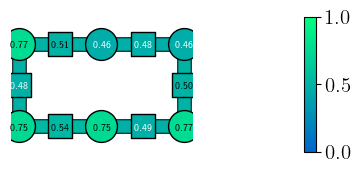

In [ ]:
from z2hex.plotting import local_observable_plot

local_observable_plot((1-observables[-1, :])/2, lattice, cmap_range=[0, 1])